In [65]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

In [66]:
df=pd.read_csv('weight-height.csv')
df.head()

,Weight,Height
0,45,120
1,58,135
2,48,123
3,60,145
4,70,160


In [67]:
df.shape

(23, 2)

Text(0, 0.5, 'Height')

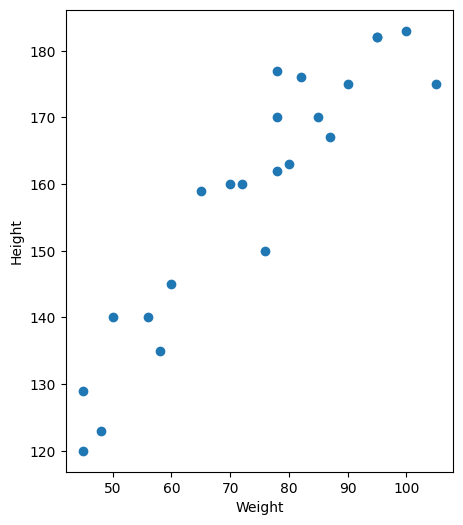

In [68]:
plt.figure(figsize=(5,6))
plt.scatter(df['Weight'],df['Height'])
plt.xlabel('Weight')
plt.ylabel('Height')

In [69]:
X=df[['Weight']]
y=df['Height']

In [70]:
from sklearn.model_selection import train_test_split

In [71]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.20,random_state=42)

In [72]:
X_train.shape,X_test.shape

((18, 1), (5, 1))

In [73]:
##Standardizing the data
from sklearn.preprocessing import StandardScaler

In [74]:
scaler=StandardScaler()
X_train=scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)

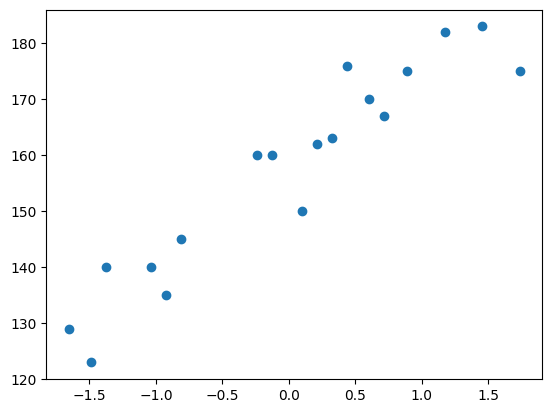

In [75]:
plt.scatter(X_train,y_train)

In [76]:
from sklearn.linear_model import LinearRegression

In [77]:
regression=LinearRegression()
regression.fit(X_train,y_train)
#y_pred=regression.predict(X_test)

LinearRegression()

In [78]:
print("the coeffeicent of the weight is ",regression.coef_)
print("the intercept is : ",regression.intercept_)

the coeffeicent of the weight is  [17.03440872]
the intercept is :  157.5


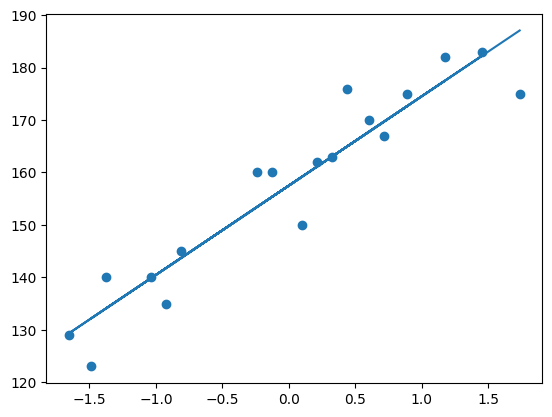

In [79]:
##seeing the best fit line
plt.scatter(X_train,y_train)
plt.plot(X_train,regression.predict(X_train))

In [80]:
y_pred=regression.predict(X_test)

In [81]:
##analysing the performance metrics
##less the errors more good the model
from sklearn.metrics import mean_squared_error,mean_absolute_error
from sklearn.metrics import r2_score
mse=mean_squared_error(y_test,y_pred)
mae=mean_absolute_error(y_test,y_pred)
rmse=np.sqrt(mse)
score=r2_score(y_test,y_pred)
print(mse)
print(mae)
print(rmse)
print(score*100)

109.77592599051664
9.822657814519232
10.477400726827081
77.6986986042344


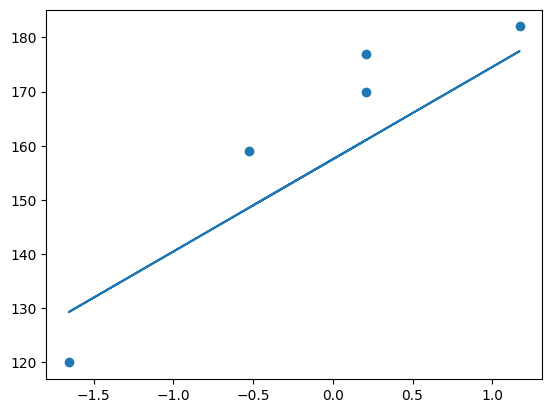

In [82]:
##plotting the graph for best fit line for the predicted resutls
plt.scatter(X_test,y_test)
plt.plot(X_test,regression.predict(X_test))

In [84]:
##predicting the new results by giving the input
scaled_w=scaler.transform([[80]])
scaled_w
print("The height of the person will be: ",regression.predict([scaled_w[0]]))

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


array([163.01076266])

In [85]:
regression.predict(scaler.transform([[80]]))

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


array([163.01076266])